In [ ]:
!pip install pyqt5 numpy matplotlib termcolor

In [3]:
import heapq
from termcolor import colored #3shan alwan (3abas)
import math
GOAL = (0, 1, 2, 3, 4, 5, 6, 7, 8)

In [4]:
#Priorities bt3tna : Up, Down, Left, Right hsb refrence
NEIGHBORS = {
    0: [(3, 'Down'), (1, 'Right')],
    1: [(4, 'Down'), (0, 'Left'), (2, 'Right')],
    2: [(5, 'Down'), (1,'Left')],
    3: [(0,'Up'), (6,'Down'), (4,'Right')],
    4: [(1, 'Up'), (7, 'Down'), (3, 'Left'), (5, 'Right')],
    5: [(2,'Up'), (8,'Down'), (4,'Left')],
    6: [(3,'Up'), (7,'Right')],
    7: [(4,'Up'), (6,'Left'), (8,'Right')],
    8: [(5,'Up'),(7,'Left')]
}
moves = { #hasa nfs el neighbors bas msh mot2keda
    'U': -3,  
    'D': 3,   
    'L': -1,  
    'R': 1   
}

In [11]:
class Node:
    def __init__(self, board, parent=None, move=None, depth=0,cost = 0):
        self.board = board
        self.parent = parent
        self.move = move
        self.depth = depth
        self.cost = cost
    def __lt__(self,other):
        return self.cost < other.cost


In [12]:
def swap(state, i, j):
    board = list(state)
    board[i], board[j] = board[j], board[i]
    return tuple(board)

def get_children(node):
    i = node.board.index(0)
    children = []
    for j, d in NEIGHBORS[i]:
        new_board = swap(node.board, i, j)
        child = Node(new_board, node, d, node.depth + 1)
        children.append(child)
    return children


In [13]:

#lw 3ozna length el path? len(moves)
def get_path(node):
    moves = []
    while node.parent != None:
        moves.append(node.move)   #han save
        node = node.parent      
    moves.reverse()               # gebna mn goal ll parent, ne3ks ba
    return moves


In [14]:

#shaklan helw bs, trust
def print_board(board):
    print("┌───┬───┬───┐")
    for r in range(3):
        row = board[r*3 : r*3+3]
        print("│" + "│".join(f" {t if t else ' '} " for t in row) + "│")
        if r < 2:
            print("├───┼───┼───┤")
    print("└───┴───┴───┘")


def print_solution(goal_node):
    nodes = []
    node = goal_node
    while node != None:
        nodes.append(node)
        node = node.parent
    nodes.reverse()

    print("Initial board:")
    print_board(nodes[0].board)

    for step, node in enumerate(nodes[1:], start=1):
        print(f"Step {step}: move {node.move}")
        print_board(node.board)

    print("Goal reached!")


In [15]:


def movePiece(board,move,blank):
    #move the number based on the move and change blacnk pos
    new = list(board)
    newBlank_position = blank + moves[move]
    new[blank],new[newBlank_position] = new[newBlank_position],new[blank]
    return tuple(new)

def HeuristicsEuclidean(board):
    h = 0
    for i,t in enumerate(board):
        if t !=0: #malnash da3wa bl fadi
            x1,y1 = divmod(i,3) #current position
            x2,y2 = divmod(t,3) #goal position
            h += math.sqrt((x1-x2)**2 + (y1-y2)**2)
    return h


def AStarEuclidean(start):
    openlist = []
    closedlist = set()
    heapq.heappush(openlist,Node(start, None, None, 0, HeuristicsEuclidean(start))) # put start node in pq
    while openlist:
        current = heapq.heappop(openlist) # get the current with the lowest cost
        if current.board == GOAL: # if goal reached
            return current
     
        closedlist.add(tuple(current.board))
        blank = current.board.index(0)
        
        for move in moves:
            #no illigal move
            if move =='U' and blank < 3:
                continue
            if move =='D' and blank > 5:
                continue
            if move =='L' and blank % 3 == 0:
                continue
            if move =='R' and blank % 3 == 2:
                continue
            # shift el piece
            newboard = movePiece(current.board, move, blank)
            if tuple(newboard) in closedlist:
                continue
            #next node
            new = Node(newboard,current,move,current.depth+1,HeuristicsEuclidean(newboard)+current.depth+1)
            heapq.heappush(openlist,new) #push in queue
    return None
                

     



In [ ]:
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from matplotlib.patches import FancyBboxPatch, Rectangle
import matplotlib
#kan msh beyet7rk
matplotlib.use('QtAgg')
import time
from IPython.display import display, clear_output


def cell_xy(index):
    row,col=divmod(index,3)
    return col,2-row
def cleanAnimation(t):
    #smooth
    return t*t*(3-2*t)
def cute_animation_for_puzzle(gnode,framespm=12,intervals=30,holdf=30):
    nodes=[]
    node=gnode
    #start from node then retrace all moves append f array 
    while node is not None:
        nodes.append(node)
        node=node.parent
    nodes.reverse()
    boards=[n.board for n in nodes]
    moves=[n.move for n in nodes]
    nmoves =len(boards) -1
    fig,ax=plt.subplots(figsize=(6,6))
    #border
    fig.patch.set_facecolor('purple')
    #background
    ax.set_facecolor('pink')
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xlim(0,3)
    ax.set_ylim(0,3)
    ax.set_aspect('equal')
    #el border el rofya3 el f nos
    ax.spines['bottom'].set_color('white')
    ax.spines['top'].set_color('white')
    ax.spines['right'].set_color('white')
    ax.spines['left'].set_color('white')
    pad = 0.06
    tiles={}
    for i in range(1,9):
        x,y=cell_xy(boards[0].index(i))
        #rounded box el gowa el haytktb feh el rkm
        patch=FancyBboxPatch((x+pad,y+pad),1-2*pad,1-2*pad,boxstyle='round,pad=0,rounding_size=0.15',facecolor='white',edgecolor='white',linewidth=2)
        ax.add_patch(patch)
        #el rkm el gowa
        text = ax.text(x+0.5,y+0.5,str(i),color='black',fontsize=20,fontweight='bold',va='center',ha='center')
        tiles[i]=(patch,text)
    for i in range(nmoves):
        for j in range(1,framespm+1):
            t=cleanAnimation(j/framespm)
            for k in range(1,9):
                #position of each tile
                x0,y0=cell_xy(boards[i].index(k))
                x1,y1=cell_xy(boards[i+1].index(k))
                x=x0+(x1-x0)*t
                y=y0+(y1-y0)*t
                patch,text=tiles[k]
                patch.set_x(x+pad)
                patch.set_y(y+pad)
                text.set_position((x+0.5,y+0.5))
            display(fig)
            clear_output(wait=True)
            time.sleep(intervals / 1000)

    ax.set_title("Goal reached!", color='white')
    display(fig)
    plt.close(fig)

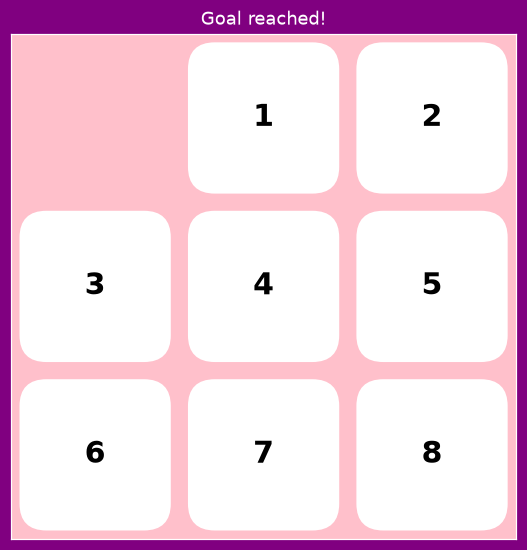

Test 1: children
Down
┌───┬───┬───┐
│ 8 │ 4 │ 6 │
├───┼───┼───┤
│ 5 │   │ 7 │
├───┼───┼───┤
│ 2 │ 3 │ 1 │
└───┴───┴───┘
Left
┌───┬───┬───┐
│   │ 8 │ 6 │
├───┼───┼───┤
│ 5 │ 4 │ 7 │
├───┼───┼───┤
│ 2 │ 3 │ 1 │
└───┴───┴───┘
Right
┌───┬───┬───┐
│ 8 │ 6 │   │
├───┼───┼───┤
│ 5 │ 4 │ 7 │
├───┼───┼───┤
│ 2 │ 3 │ 1 │
└───┴───┴───┘
Test 2: path
['Up', 'Left', 'Left']
Test 3: full solution
Initial board:
┌───┬───┬───┐
│ 8 │   │ 6 │
├───┼───┼───┤
│ 5 │ 4 │ 7 │
├───┼───┼───┤
│ 2 │ 3 │ 1 │
└───┴───┴───┘
Step 1: move Up
┌───┬───┬───┐
│ 1 │ 2 │   │
├───┼───┼───┤
│ 3 │ 4 │ 5 │
├───┼───┼───┤
│ 6 │ 7 │ 8 │
└───┴───┴───┘
Step 2: move Left
┌───┬───┬───┐
│ 1 │   │ 2 │
├───┼───┼───┤
│ 3 │ 4 │ 5 │
├───┼───┼───┤
│ 6 │ 7 │ 8 │
└───┴───┴───┘
Step 3: move Left
┌───┬───┬───┐
│   │ 1 │ 2 │
├───┼───┼───┤
│ 3 │ 4 │ 5 │
├───┼───┼───┤
│ 6 │ 7 │ 8 │
└───┴───┴───┘
Goal reached!


In [45]:
#mesh ana eli 3mla el test

start = (8, 0, 6, 5, 4, 7, 2, 3, 1)
solution = AStarEuclidean(start)
# Test 1: children of the start (expect 3: Up, Down, Left)
if solution:
    print("A* solution:", get_path(solution))
    #B2T PINKKKK
    cute_animation_for_puzzle(solution)
start_node = Node(start) 
print("Test 1: children")
for child in get_children(start_node):
    print(child.move)
    print_board(child.board)

# Build a small path by hand
a = Node((1, 2, 0, 3, 4, 5, 6, 7, 8), start_node, 'Up', 1)
b = Node((1, 0, 2, 3, 4, 5, 6, 7, 8), a, 'Left', 2)
c = Node(GOAL, b, 'Left', 3)

# Test 2: get_path (expect ['Up', 'Left', 'Left'])
print("Test 2: path")
print(get_path(c))

# Test 3: print_solution (initial board, 3 steps, goal reached)
print("Test 3: full solution")
print_solution(c)